In [2]:
# # Step 01.8 — Class Centroid Analysis

# ## Objective

# This analysis evaluates class-level cross-modal representation compatibility using
# class centroids.

# A centroid represents the average embedding of all samples belonging to a
# specific class within a modality.

# For each modality, two centroids are calculated:

# - NON-ASD centroid
# - ASD centroid

# The analysis compares:

# 1. Same-class centroids across modalities
# 2. Different-class centroids across modalities
# 3. Cosine similarity between class-level representations
# 4. Euclidean distance between class-level representations
# 5. Overall class-level knowledge compatibility

# ## Methodological Principle

# This is a knowledge-level cross-modal analysis.

# No patient-level correspondence is assumed because the Genetic, Behavioral,
# and Environmental datasets contain different individuals.

# The comparison is performed only between aggregate class-level learned
# representations.

In [3]:
# ============================================================
# STEP 01.8 — CLASS CENTROID ANALYSIS
# CELL 2 — INITIALIZATION
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import cosine_similarity

print("=" * 100)
print("STEP 01.8 — CLASS CENTROID ANALYSIS")
print("=" * 100)

print("\nAnalysis Type:")
print("Knowledge-Level Cross-Modal Representation Analysis")

print("\nPatient-Level Matching:")
print("NOT USED")

print("\nPrimary Objective:")
print("Compare aggregate ASD and NON-ASD knowledge representations")
print("across Genetic, Behavioral, and Environmental modalities.")


# ------------------------------------------------------------
# PROJECT ROOT RESOLUTION
# ------------------------------------------------------------

current_dir = Path.cwd()

PROJECT_ROOT = None

for parent in [current_dir] + list(current_dir.parents):
    
    if (
        (parent / "05_multimodal_fusion").exists()
        and (parent / "Genetic_Model").exists()
    ):
        PROJECT_ROOT = parent
        break


if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root could not be located."
    )


EMBEDDING_DIR = (
    PROJECT_ROOT
    / "05_multimodal_fusion"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)


REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


print("\nProject Root:")
print(PROJECT_ROOT)

print("\nEmbedding Directory:")
print(EMBEDDING_DIR)

print("\nReport Directory:")
print(REPORT_DIR)

print("\nFigure Directory:")
print(FIGURE_DIR)

print("\n" + "=" * 100)
print("INITIALIZATION COMPLETED")
print("=" * 100)

STEP 01.8 — CLASS CENTROID ANALYSIS

Analysis Type:
Knowledge-Level Cross-Modal Representation Analysis

Patient-Level Matching:
NOT USED

Primary Objective:
Compare aggregate ASD and NON-ASD knowledge representations
across Genetic, Behavioral, and Environmental modalities.

Project Root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Embedding Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\05_multimodal_fusion

Report Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports

Figure Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures

INITIALIZATION COMPLETED


In [4]:
# ============================================================
# CELL 3 — LOAD FROZEN 32D EMBEDDINGS
# ============================================================

print("=" * 100)
print("LOADING FROZEN BASELINE REPRESENTATIONS")
print("=" * 100)


# ------------------------------------------------------------
# LOAD GENETIC
# ------------------------------------------------------------

genetic_embeddings = np.load(
    EMBEDDING_DIR / "genetic_32d_normalized.npy"
)

genetic_labels = np.load(
    EMBEDDING_DIR / "genetic_targets.npy"
)


# ------------------------------------------------------------
# LOAD BEHAVIORAL
# ------------------------------------------------------------

behavioral_embeddings = np.load(
    EMBEDDING_DIR / "behavioral_32d_normalized.npy"
)

behavioral_labels = np.load(
    EMBEDDING_DIR / "behavioral_targets.npy"
)


# ------------------------------------------------------------
# LOAD ENVIRONMENTAL
# ------------------------------------------------------------

environmental_embeddings = np.load(
    EMBEDDING_DIR / "environmental_32d_normalized.npy"
)

environmental_labels = np.load(
    EMBEDDING_DIR / "environmental_targets.npy"
)


# ------------------------------------------------------------
# ORGANIZE MODALITIES
# ------------------------------------------------------------

modalities = {
    
    "Genetic": {
        "embeddings": genetic_embeddings,
        "labels": genetic_labels
    },
    
    "Behavioral": {
        "embeddings": behavioral_embeddings,
        "labels": behavioral_labels
    },
    
    "Environmental": {
        "embeddings": environmental_embeddings,
        "labels": environmental_labels
    }
}


# ------------------------------------------------------------
# DISPLAY SUMMARY
# ------------------------------------------------------------

for modality_name, data in modalities.items():
    
    embeddings = data["embeddings"]
    labels = data["labels"]
    
    print(f"\n{modality_name.upper()}")
    print("-" * 70)
    
    print("Embedding shape :", embeddings.shape)
    print("Label shape     :", labels.shape)
    print("Unique labels   :", np.unique(labels))
    
    unique, counts = np.unique(
        labels,
        return_counts=True
    )
    
    class_distribution = dict(
        zip(unique, counts)
    )
    
    print("Class distribution:", class_distribution)


print("\n" + "=" * 100)
print("ALL THREE MODALITIES LOADED SUCCESSFULLY")
print("=" * 100)

LOADING FROZEN BASELINE REPRESENTATIONS

GENETIC
----------------------------------------------------------------------
Embedding shape : (116, 32)
Label shape     : (116,)
Unique labels   : [0 1]
Class distribution: {np.int64(0): np.int64(29), np.int64(1): np.int64(87)}

BEHAVIORAL
----------------------------------------------------------------------
Embedding shape : (880, 32)
Label shape     : (880,)
Unique labels   : [0 1]
Class distribution: {np.int64(0): np.int64(439), np.int64(1): np.int64(441)}

ENVIRONMENTAL
----------------------------------------------------------------------
Embedding shape : (47768, 32)
Label shape     : (47768,)
Unique labels   : [0 1]
Class distribution: {np.int64(0): np.int64(45650), np.int64(1): np.int64(2118)}

ALL THREE MODALITIES LOADED SUCCESSFULLY


In [5]:
# ============================================================
# CELL 4 — COMPUTE CLASS CENTROIDS
# ============================================================

print("=" * 100)
print("COMPUTING CLASS-LEVEL REPRESENTATION CENTROIDS")
print("=" * 100)


class_names = {
    0: "NON-ASD",
    1: "ASD"
}


centroids = {}
centroid_records = []


for modality_name, data in modalities.items():
    
    embeddings = data["embeddings"]
    labels = data["labels"]
    
    print(f"\n{modality_name.upper()}")
    print("-" * 70)
    
    centroids[modality_name] = {}
    
    
    for class_label in sorted(np.unique(labels)):
        
        # Select all embeddings belonging to this class
        class_embeddings = embeddings[
            labels == class_label
        ]
        
        # Compute centroid
        centroid = np.mean(
            class_embeddings,
            axis=0
        )
        
        # Store centroid
        centroids[modality_name][class_label] = centroid
        
        # Calculate centroid L2 norm
        centroid_norm = np.linalg.norm(
            centroid
        )
        
        centroid_records.append({
            
            "Modality": modality_name,
            
            "Class_Label": class_label,
            
            "Class_Name": class_names[class_label],
            
            "Samples_In_Class": len(class_embeddings),
            
            "Centroid_Dimension": len(centroid),
            
            "Centroid_L2_Norm": centroid_norm
            
        })
        
        
        print(
            f"{class_names[class_label]:8s} | "
            f"Samples: {len(class_embeddings):6d} | "
            f"Centroid Shape: {centroid.shape} | "
            f"L2 Norm: {centroid_norm:.6f}"
        )


# ------------------------------------------------------------
# CREATE SUMMARY TABLE
# ------------------------------------------------------------

centroid_summary_df = pd.DataFrame(
    centroid_records
)


print("\n" + "=" * 100)
print("CLASS CENTROID SUMMARY")
print("=" * 100)

display(centroid_summary_df)


# ------------------------------------------------------------
# SAVE REPORT
# ------------------------------------------------------------

centroid_summary_path = (
    REPORT_DIR
    / "01_08_class_centroid_summary.csv"
)

centroid_summary_df.to_csv(
    centroid_summary_path,
    index=False
)


print("\nCentroid summary saved:")
print(centroid_summary_path)


print("\n" + "=" * 100)
print("CLASS CENTROIDS COMPUTED SUCCESSFULLY")
print("=" * 100)

COMPUTING CLASS-LEVEL REPRESENTATION CENTROIDS

GENETIC
----------------------------------------------------------------------
NON-ASD  | Samples:     29 | Centroid Shape: (32,) | L2 Norm: 1.274148
ASD      | Samples:     87 | Centroid Shape: (32,) | L2 Norm: 0.424716

BEHAVIORAL
----------------------------------------------------------------------
NON-ASD  | Samples:    439 | Centroid Shape: (32,) | L2 Norm: 3.974837
ASD      | Samples:    441 | Centroid Shape: (32,) | L2 Norm: 3.956811

ENVIRONMENTAL
----------------------------------------------------------------------
NON-ASD  | Samples:  45650 | Centroid Shape: (32,) | L2 Norm: 0.055577
ASD      | Samples:   2118 | Centroid Shape: (32,) | L2 Norm: 1.197868

CLASS CENTROID SUMMARY


,Modality,Class_Label,Class_Name,Samples_In_Class,Centroid_Dimension,Centroid_L2_Norm
0,Genetic,0,NON-ASD,29,32,1.274148
1,Genetic,1,ASD,87,32,0.424716
2,Behavioral,0,NON-ASD,439,32,3.974837
3,Behavioral,1,ASD,441,32,3.956811
4,Environmental,0,NON-ASD,45650,32,0.055577
5,Environmental,1,ASD,2118,32,1.197868



Centroid summary saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_08_class_centroid_summary.csv

CLASS CENTROIDS COMPUTED SUCCESSFULLY


In [6]:
# ============================================================
# CELL 5 — CREATE CENTROID COMPARISON MATRIX
# ============================================================

print("=" * 100)
print("BUILDING CENTROID COMPARISON MATRIX")
print("=" * 100)


centroid_vectors = []
centroid_labels = []
centroid_metadata = []


for modality_name in modalities.keys():
    
    for class_label in [0, 1]:
        
        centroid_vectors.append(
            centroids[modality_name][class_label]
        )
        
        label_name = (
            f"{modality_name} — "
            f"{class_names[class_label]}"
        )
        
        centroid_labels.append(
            label_name
        )
        
        centroid_metadata.append({
            "Representation": label_name,
            "Modality": modality_name,
            "Class_Label": class_label,
            "Class_Name": class_names[class_label]
        })


# Convert to NumPy matrix

centroid_matrix = np.vstack(
    centroid_vectors
)

centroid_metadata_df = pd.DataFrame(
    centroid_metadata
)


print("\nCentroid Matrix Shape:")
print(centroid_matrix.shape)

print("\nExpected:")
print("6 class-level representations × 32 dimensions")

print("\nCentroid Representations:")

for label in centroid_labels:
    print("•", label)


print("\n" + "=" * 100)
print("CENTROID MATRIX READY")
print("=" * 100)

BUILDING CENTROID COMPARISON MATRIX

Centroid Matrix Shape:
(6, 32)

Expected:
6 class-level representations × 32 dimensions

Centroid Representations:
• Genetic — NON-ASD
• Genetic — ASD
• Behavioral — NON-ASD
• Behavioral — ASD
• Environmental — NON-ASD
• Environmental — ASD

CENTROID MATRIX READY


In [7]:
# ============================================================
# CELL 6 — CENTROID COSINE SIMILARITY
# ============================================================

print("=" * 100)
print("CLASS CENTROID COSINE SIMILARITY ANALYSIS")
print("=" * 100)


# ------------------------------------------------------------
# COMPUTE COSINE SIMILARITY MATRIX
# ------------------------------------------------------------

centroid_cosine_matrix = cosine_similarity(
    centroid_matrix
)


centroid_cosine_df = pd.DataFrame(
    
    centroid_cosine_matrix,
    
    index=centroid_labels,
    
    columns=centroid_labels
)


print("\nCOSINE SIMILARITY MATRIX")
print("-" * 100)

display(
    centroid_cosine_df.round(4)
)


# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

cosine_matrix_path = (
    REPORT_DIR
    / "01_08_centroid_cosine_similarity_matrix.csv"
)

centroid_cosine_df.to_csv(
    cosine_matrix_path
)


# ------------------------------------------------------------
# EXTRACT CROSS-MODAL COMPARISONS
# ------------------------------------------------------------

cross_modal_records = []


for i in range(len(centroid_metadata)):
    
    for j in range(i + 1, len(centroid_metadata)):
        
        first = centroid_metadata[i]
        second = centroid_metadata[j]
        
        # Skip within-modality comparisons here
        if first["Modality"] == second["Modality"]:
            continue
        
        similarity = centroid_cosine_matrix[i, j]
        
        same_class = (
            first["Class_Label"]
            ==
            second["Class_Label"]
        )
        
        cross_modal_records.append({
            
            "Representation_1":
                first["Representation"],
            
            "Representation_2":
                second["Representation"],
            
            "Modality_1":
                first["Modality"],
            
            "Modality_2":
                second["Modality"],
            
            "Class_1":
                first["Class_Name"],
            
            "Class_2":
                second["Class_Name"],
            
            "Relationship":
                (
                    "Same Class"
                    if same_class
                    else "Different Class"
                ),
            
            "Cosine_Similarity":
                similarity
            
        })


cross_modal_similarity_df = pd.DataFrame(
    cross_modal_records
)


print("\n" + "=" * 100)
print("CROSS-MODAL CENTROID COMPARISONS")
print("=" * 100)

display(
    cross_modal_similarity_df.round(4)
)


# Save

cross_modal_path = (
    REPORT_DIR
    / "01_08_cross_modal_centroid_similarity.csv"
)

cross_modal_similarity_df.to_csv(
    cross_modal_path,
    index=False
)


print("\nReports saved:")
print(cosine_matrix_path)
print(cross_modal_path)


print("\n" + "=" * 100)
print("CENTROID COSINE ANALYSIS COMPLETED")
print("=" * 100)

CLASS CENTROID COSINE SIMILARITY ANALYSIS

COSINE SIMILARITY MATRIX
----------------------------------------------------------------------------------------------------


,Genetic — NON-ASD,Genetic — ASD,Behavioral — NON-ASD,Behavioral — ASD,Environmental — NON-ASD,Environmental — ASD
Genetic — NON-ASD,1.0000,-1.0000,-0.0866,0.0866,-0.2808,0.2808
Genetic — ASD,-1.0000,1.0000,0.0866,-0.0866,0.2808,-0.2808
Behavioral — NON-ASD,-0.0866,0.0866,1.0000,-1.0000,0.2291,-0.2291
Behavioral — ASD,0.0866,-0.0866,-1.0000,1.0000,-0.2291,0.2291
Environmental — NON-ASD,-0.2808,0.2808,0.2291,-0.2291,1.0000,-1.0000
Environmental — ASD,0.2808,-0.2808,-0.2291,0.2291,-1.0000,1.0000



CROSS-MODAL CENTROID COMPARISONS


,Representation_1,Representation_2,Modality_1,Modality_2,Class_1,Class_2,Relationship,Cosine_Similarity
0,Genetic — NON-ASD,Behavioral — NON-ASD,Genetic,Behavioral,NON-ASD,NON-ASD,Same Class,-0.0866
1,Genetic — NON-ASD,Behavioral — ASD,Genetic,Behavioral,NON-ASD,ASD,Different Class,0.0866
2,Genetic — NON-ASD,Environmental — NON-ASD,Genetic,Environmental,NON-ASD,NON-ASD,Same Class,-0.2808
3,Genetic — NON-ASD,Environmental — ASD,Genetic,Environmental,NON-ASD,ASD,Different Class,0.2808
4,Genetic — ASD,Behavioral — NON-ASD,Genetic,Behavioral,ASD,NON-ASD,Different Class,0.0866
5,Genetic — ASD,Behavioral — ASD,Genetic,Behavioral,ASD,ASD,Same Class,-0.0866
6,Genetic — ASD,Environmental — NON-ASD,Genetic,Environmental,ASD,NON-ASD,Different Class,0.2808
7,Genetic — ASD,Environmental — ASD,Genetic,Environmental,ASD,ASD,Same Class,-0.2808
8,Behavioral — NON-ASD,Environmental — NON-ASD,Behavioral,Environmental,NON-ASD,NON-ASD,Same Class,0.2291
9,Behavioral — NON-ASD,Environmental — ASD,Behavioral,Environmental,NON-ASD,ASD,Different Class,-0.2291



Reports saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_08_centroid_cosine_similarity_matrix.csv
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_08_cross_modal_centroid_similarity.csv

CENTROID COSINE ANALYSIS COMPLETED


In [8]:
# ============================================================
# CELL 7 — SAME-CLASS VS DIFFERENT-CLASS CENTROID ANALYSIS
# ============================================================

print("=" * 100)
print("SAME-CLASS VS DIFFERENT-CLASS CENTROID COMPATIBILITY")
print("=" * 100)


# ------------------------------------------------------------
# GROUP COMPARISONS
# ------------------------------------------------------------

same_class_df = cross_modal_similarity_df[
    cross_modal_similarity_df["Relationship"]
    == "Same Class"
].copy()


different_class_df = cross_modal_similarity_df[
    cross_modal_similarity_df["Relationship"]
    == "Different Class"
].copy()


# ------------------------------------------------------------
# SUMMARY STATISTICS
# ------------------------------------------------------------

same_class_mean = (
    same_class_df["Cosine_Similarity"].mean()
)

same_class_std = (
    same_class_df["Cosine_Similarity"].std()
)


different_class_mean = (
    different_class_df["Cosine_Similarity"].mean()
)

different_class_std = (
    different_class_df["Cosine_Similarity"].std()
)


compatibility_gap = (
    same_class_mean
    -
    different_class_mean
)


summary_data = [
    
    {
        "Comparison_Type": "Same Class",
        "Number_of_Comparisons": len(same_class_df),
        "Mean_Cosine_Similarity": same_class_mean,
        "Std_Cosine_Similarity": same_class_std
    },
    
    {
        "Comparison_Type": "Different Class",
        "Number_of_Comparisons": len(different_class_df),
        "Mean_Cosine_Similarity": different_class_mean,
        "Std_Cosine_Similarity": different_class_std
    }
]


compatibility_summary_df = pd.DataFrame(
    summary_data
)


print("\nSAME-CLASS COMPARISONS")
print("-" * 100)

display(
    same_class_df[
        [
            "Representation_1",
            "Representation_2",
            "Cosine_Similarity"
        ]
    ].round(4)
)


print("\nDIFFERENT-CLASS COMPARISONS")
print("-" * 100)

display(
    different_class_df[
        [
            "Representation_1",
            "Representation_2",
            "Cosine_Similarity"
        ]
    ].round(4)
)


print("\n" + "=" * 100)
print("COMPATIBILITY SUMMARY")
print("=" * 100)

display(
    compatibility_summary_df.round(4)
)


print(f"\nMean Same-Class Similarity      : {same_class_mean:.6f}")
print(f"Mean Different-Class Similarity : {different_class_mean:.6f}")
print(f"Class Compatibility Gap         : {compatibility_gap:.6f}")


if compatibility_gap > 0:
    
    interpretation = (
        "Same-class centroids show higher average cross-modal similarity. "
        "This indicates positive class-level knowledge compatibility."
    )
    
else:
    
    interpretation = (
        "Same-class centroids do not show higher average cross-modal similarity. "
        "This indicates incomplete or modality-dependent alignment."
    )


print("\nInterpretation:")
print(interpretation)


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

compatibility_path = (
    REPORT_DIR
    / "01_08_same_vs_different_class_centroid_summary.csv"
)

compatibility_summary_df.to_csv(
    compatibility_path,
    index=False
)


print("\nReport saved:")
print(compatibility_path)

SAME-CLASS VS DIFFERENT-CLASS CENTROID COMPATIBILITY

SAME-CLASS COMPARISONS
----------------------------------------------------------------------------------------------------


,Representation_1,Representation_2,Cosine_Similarity
0,Genetic — NON-ASD,Behavioral — NON-ASD,-0.0866
2,Genetic — NON-ASD,Environmental — NON-ASD,-0.2808
5,Genetic — ASD,Behavioral — ASD,-0.0866
7,Genetic — ASD,Environmental — ASD,-0.2808
8,Behavioral — NON-ASD,Environmental — NON-ASD,0.2291
11,Behavioral — ASD,Environmental — ASD,0.2291



DIFFERENT-CLASS COMPARISONS
----------------------------------------------------------------------------------------------------


,Representation_1,Representation_2,Cosine_Similarity
1,Genetic — NON-ASD,Behavioral — ASD,0.0866
3,Genetic — NON-ASD,Environmental — ASD,0.2808
4,Genetic — ASD,Behavioral — NON-ASD,0.0866
6,Genetic — ASD,Environmental — NON-ASD,0.2808
9,Behavioral — NON-ASD,Environmental — ASD,-0.2291
10,Behavioral — ASD,Environmental — NON-ASD,-0.2291



COMPATIBILITY SUMMARY


,Comparison_Type,Number_of_Comparisons,Mean_Cosine_Similarity,Std_Cosine_Similarity
0,Same Class,6,-0.0461,0.2302
1,Different Class,6,0.0461,0.2302



Mean Same-Class Similarity      : -0.046105
Mean Different-Class Similarity : 0.046105
Class Compatibility Gap         : -0.092210

Interpretation:
Same-class centroids do not show higher average cross-modal similarity. This indicates incomplete or modality-dependent alignment.

Report saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_08_same_vs_different_class_centroid_summary.csv


In [9]:
# ============================================================
# CELL 8 — CENTROID EUCLIDEAN DISTANCE ANALYSIS
# ============================================================

print("=" * 100)
print("CLASS CENTROID EUCLIDEAN DISTANCE ANALYSIS")
print("=" * 100)


# ------------------------------------------------------------
# COMPUTE PAIRWISE EUCLIDEAN DISTANCE
# ------------------------------------------------------------

n_centroids = len(centroid_matrix)

distance_matrix = np.zeros(
    (n_centroids, n_centroids)
)


for i in range(n_centroids):
    
    for j in range(n_centroids):
        
        distance_matrix[i, j] = np.linalg.norm(
            centroid_matrix[i]
            -
            centroid_matrix[j]
        )


distance_df = pd.DataFrame(
    
    distance_matrix,
    
    index=centroid_labels,
    
    columns=centroid_labels
)


print("\nEUCLIDEAN DISTANCE MATRIX")
print("-" * 100)

display(
    distance_df.round(4)
)


# ------------------------------------------------------------
# SAVE MATRIX
# ------------------------------------------------------------

distance_matrix_path = (
    REPORT_DIR
    / "01_08_centroid_euclidean_distance_matrix.csv"
)

distance_df.to_csv(
    distance_matrix_path
)


# ------------------------------------------------------------
# CROSS-MODAL DISTANCE RECORDS
# ------------------------------------------------------------

distance_records = []


for i in range(len(centroid_metadata)):
    
    for j in range(i + 1, len(centroid_metadata)):
        
        first = centroid_metadata[i]
        second = centroid_metadata[j]
        
        if first["Modality"] == second["Modality"]:
            continue
        
        same_class = (
            first["Class_Label"]
            ==
            second["Class_Label"]
        )
        
        
        distance_records.append({
            
            "Representation_1":
                first["Representation"],
            
            "Representation_2":
                second["Representation"],
            
            "Relationship":
                (
                    "Same Class"
                    if same_class
                    else "Different Class"
                ),
            
            "Euclidean_Distance":
                distance_matrix[i, j]
        })


cross_modal_distance_df = pd.DataFrame(
    distance_records
)


# ------------------------------------------------------------
# SAME VS DIFFERENT CLASS DISTANCE
# ------------------------------------------------------------

same_distance = cross_modal_distance_df[
    cross_modal_distance_df["Relationship"]
    == "Same Class"
]["Euclidean_Distance"]


different_distance = cross_modal_distance_df[
    cross_modal_distance_df["Relationship"]
    == "Different Class"
]["Euclidean_Distance"]


print("\n" + "=" * 100)
print("DISTANCE SUMMARY")
print("=" * 100)

print(
    f"\nMean Same-Class Distance      : "
    f"{same_distance.mean():.6f}"
)

print(
    f"Mean Different-Class Distance : "
    f"{different_distance.mean():.6f}"
)


distance_gap = (
    different_distance.mean()
    -
    same_distance.mean()
)


print(
    f"Distance Separation Gap       : "
    f"{distance_gap:.6f}"
)


if distance_gap > 0:
    
    print(
        "\nInterpretation:"
    )
    
    print(
        "Same-class centroids are closer than different-class centroids "
        "on average, supporting class-level cross-modal compatibility."
    )

else:
    
    print(
        "\nInterpretation:"
    )
    
    print(
        "Same-class centroids are not consistently closer than "
        "different-class centroids, indicating incomplete alignment."
    )


# Save

cross_distance_path = (
    REPORT_DIR
    / "01_08_cross_modal_centroid_distances.csv"
)

cross_modal_distance_df.to_csv(
    cross_distance_path,
    index=False
)


print("\nReports saved:")
print(distance_matrix_path)
print(cross_distance_path)


print("\n" + "=" * 100)
print("EUCLIDEAN DISTANCE ANALYSIS COMPLETED")
print("=" * 100)

CLASS CENTROID EUCLIDEAN DISTANCE ANALYSIS

EUCLIDEAN DISTANCE MATRIX
----------------------------------------------------------------------------------------------------


,Genetic — NON-ASD,Genetic — ASD,Behavioral — NON-ASD,Behavioral — ASD,Environmental — NON-ASD,Environmental — ASD
Genetic — NON-ASD,0.0000,1.6989,4.2778,4.0505,1.2909,1.4836
Genetic — ASD,1.6989,0.0000,3.9607,4.0159,0.4126,1.3788
Behavioral — NON-ASD,4.2778,3.9607,0.0000,7.9316,3.9625,4.4064
Behavioral — ASD,4.0505,4.0159,7.9316,0.0000,3.9699,3.8626
Environmental — NON-ASD,1.2909,0.4126,3.9625,3.9699,0.0000,1.2534
Environmental — ASD,1.4836,1.3788,4.4064,3.8626,1.2534,0.0000



DISTANCE SUMMARY

Mean Same-Class Distance      : 3.131410
Mean Different-Class Distance : 3.047280
Distance Separation Gap       : -0.084130

Interpretation:
Same-class centroids are not consistently closer than different-class centroids, indicating incomplete alignment.

Reports saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_08_centroid_euclidean_distance_matrix.csv
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_08_cross_modal_centroid_distances.csv

EUCLIDEAN DISTANCE ANALYSIS COMPLETED


GENERATING CENTROID SIMILARITY VISUALIZATION


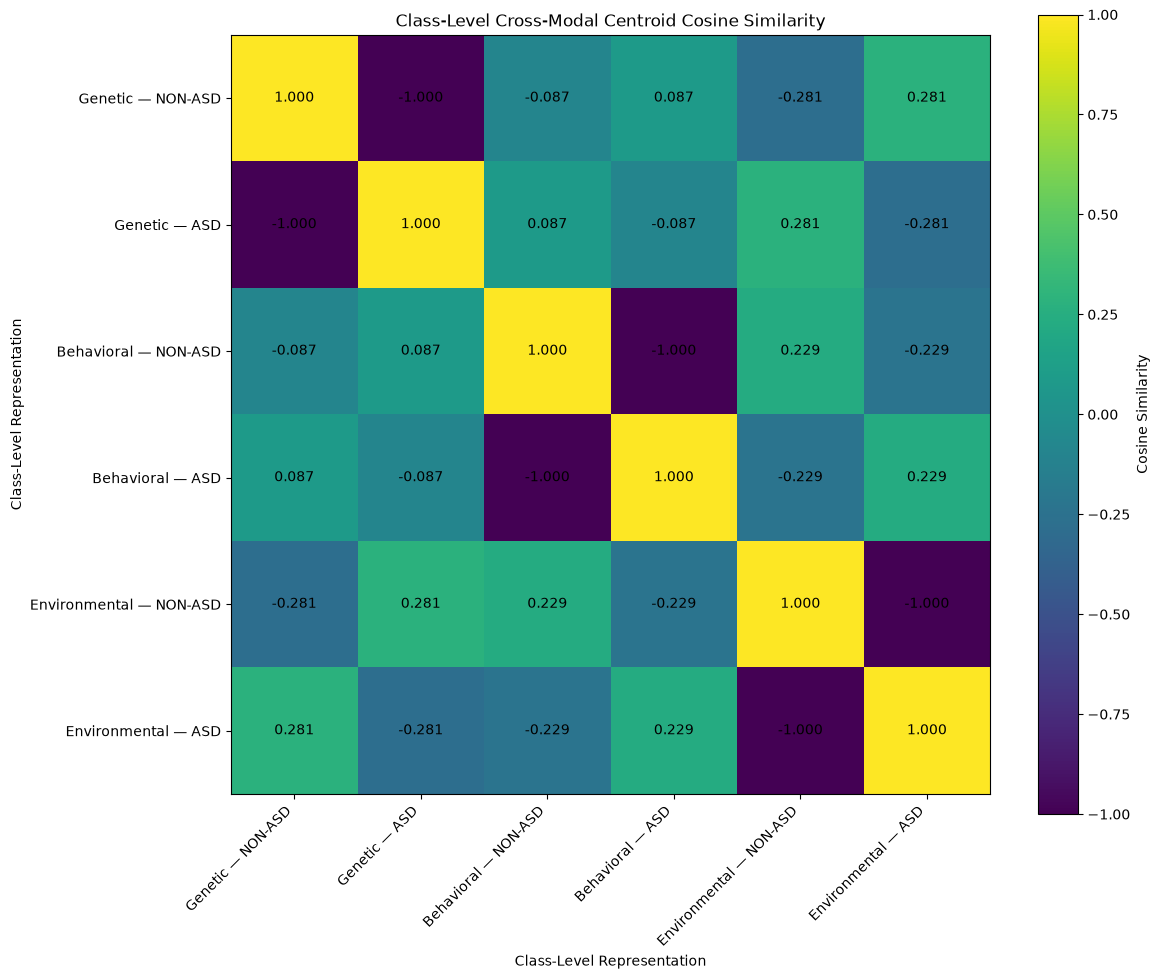


Figure saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_08_centroid_cosine_similarity_heatmap.png

VISUALIZATION COMPLETED


In [10]:
# ============================================================
# CELL 9 — VISUALIZE CENTROID COSINE SIMILARITY
# ============================================================

print("=" * 100)
print("GENERATING CENTROID SIMILARITY VISUALIZATION")
print("=" * 100)


plt.figure(figsize=(12, 10))

image = plt.imshow(
    centroid_cosine_matrix,
    interpolation="nearest"
)

plt.colorbar(
    image,
    label="Cosine Similarity"
)

plt.xticks(
    range(len(centroid_labels)),
    centroid_labels,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(centroid_labels)),
    centroid_labels
)


# Add values inside cells

for i in range(len(centroid_labels)):
    
    for j in range(len(centroid_labels)):
        
        plt.text(
            j,
            i,
            f"{centroid_cosine_matrix[i, j]:.3f}",
            ha="center",
            va="center"
        )


plt.title(
    "Class-Level Cross-Modal Centroid Cosine Similarity"
)

plt.xlabel(
    "Class-Level Representation"
)

plt.ylabel(
    "Class-Level Representation"
)

plt.tight_layout()


# Save figure

figure_path = (
    FIGURE_DIR
    / "01_08_centroid_cosine_similarity_heatmap.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nFigure saved:")
print(figure_path)


print("\n" + "=" * 100)
print("VISUALIZATION COMPLETED")
print("=" * 100)

In [11]:
# ============================================================
# CELL 10 — FINAL CLASS CENTROID ANALYSIS SUMMARY
# ============================================================

print("=" * 100)
print("STEP 01.8 — FINAL CLASS CENTROID ANALYSIS SUMMARY")
print("=" * 100)


# ------------------------------------------------------------
# CREATE FINAL SUMMARY
# ------------------------------------------------------------

final_summary = pd.DataFrame([
    
    {
        "Metric": "Mean Same-Class Cosine Similarity",
        "Value": same_class_mean
    },
    
    {
        "Metric": "Mean Different-Class Cosine Similarity",
        "Value": different_class_mean
    },
    
    {
        "Metric": "Cosine Compatibility Gap",
        "Value": compatibility_gap
    },
    
    {
        "Metric": "Mean Same-Class Euclidean Distance",
        "Value": same_distance.mean()
    },
    
    {
        "Metric": "Mean Different-Class Euclidean Distance",
        "Value": different_distance.mean()
    },
    
    {
        "Metric": "Distance Separation Gap",
        "Value": distance_gap
    }
])


print("\nFINAL QUANTITATIVE SUMMARY")
print("-" * 100)

display(
    final_summary.round(6)
)


# ------------------------------------------------------------
# SCIENTIFIC INTERPRETATION
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("SCIENTIFIC INTERPRETATION")
print("=" * 100)


if compatibility_gap > 0 and distance_gap > 0:
    
    conclusion = (
        "The centroid analysis provides evidence of positive class-level "
        "cross-modal compatibility. Same-class knowledge representations "
        "are, on average, more directionally similar and spatially closer "
        "than different-class representations."
    )
    
elif compatibility_gap > 0 or distance_gap > 0:
    
    conclusion = (
        "The centroid analysis shows partial class-level cross-modal "
        "compatibility. Some metrics support shared class-level structure, "
        "while others indicate remaining modality-specific differences."
    )
    
else:
    
    conclusion = (
        "The centroid analysis indicates limited natural class-level "
        "alignment between modalities. This suggests that explicit "
        "cross-modal learning may be necessary to bridge the modality gap."
    )


print("\n" + conclusion)


print("\nMethodological Note:")
print(
    "This analysis compares aggregate class-level representations."
)

print(
    "No patient identity correspondence was used or assumed."
)

print(
    "The results evaluate knowledge-level compatibility between "
    "independently learned modality representations."
)


# ------------------------------------------------------------
# SAVE FINAL REPORT
# ------------------------------------------------------------

final_summary_path = (
    REPORT_DIR
    / "01_08_class_centroid_final_summary.csv"
)

final_summary.to_csv(
    final_summary_path,
    index=False
)


print("\n" + "=" * 100)
print("✓ STEP 01.8 COMPLETED")
print("✓ CLASS-LEVEL KNOWLEDGE REPRESENTATIONS ANALYZED")
print("✓ NO PATIENT-LEVEL ASSUMPTIONS MADE")
print("✓ CROSS-MODAL CENTROID COMPATIBILITY EVALUATED")
print("=" * 100)


print("\nGenerated Reports:")
print("1. 01_08_class_centroid_summary.csv")
print("2. 01_08_centroid_cosine_similarity_matrix.csv")
print("3. 01_08_cross_modal_centroid_similarity.csv")
print("4. 01_08_same_vs_different_class_centroid_summary.csv")
print("5. 01_08_centroid_euclidean_distance_matrix.csv")
print("6. 01_08_cross_modal_centroid_distances.csv")
print("7. 01_08_class_centroid_final_summary.csv")


print("\nGenerated Figure:")
print("1. 01_08_centroid_cosine_similarity_heatmap.png")


print("\nNext Logical Step:")
print("01.9 — Label and Class Distribution Validation")

STEP 01.8 — FINAL CLASS CENTROID ANALYSIS SUMMARY

FINAL QUANTITATIVE SUMMARY
----------------------------------------------------------------------------------------------------


,Metric,Value
0,Mean Same-Class Cosine Similarity,-0.046105
1,Mean Different-Class Cosine Similarity,0.046105
2,Cosine Compatibility Gap,-0.092210
3,Mean Same-Class Euclidean Distance,3.131410
4,Mean Different-Class Euclidean Distance,3.047280
5,Distance Separation Gap,-0.084130



SCIENTIFIC INTERPRETATION

The centroid analysis indicates limited natural class-level alignment between modalities. This suggests that explicit cross-modal learning may be necessary to bridge the modality gap.

Methodological Note:
This analysis compares aggregate class-level representations.
No patient identity correspondence was used or assumed.
The results evaluate knowledge-level compatibility between independently learned modality representations.

✓ STEP 01.8 COMPLETED
✓ CLASS-LEVEL KNOWLEDGE REPRESENTATIONS ANALYZED
✓ NO PATIENT-LEVEL ASSUMPTIONS MADE
✓ CROSS-MODAL CENTROID COMPATIBILITY EVALUATED

Generated Reports:
1. 01_08_class_centroid_summary.csv
2. 01_08_centroid_cosine_similarity_matrix.csv
3. 01_08_cross_modal_centroid_similarity.csv
4. 01_08_same_vs_different_class_centroid_summary.csv
5. 01_08_centroid_euclidean_distance_matrix.csv
6. 01_08_cross_modal_centroid_distances.csv
7. 01_08_class_centroid_final_summary.csv

Generated Figure:
1. 01_08_centroid_cosine_simila